# Quickstart: from a folder of NIfTI files to factors

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ContextLab/htfa/blob/main/docs/tutorials/01_quickstart.ipynb)

This tutorial fits HTFA to a folder of NIfTI files with a single call to `htfa.fit`, then walks through the results object. A fit of one subject is shown as well. The data are synthetic, so the factors that the fit should recover are known and can be compared with the estimates.

The next cell installs htfa from GitHub if it is not installed (`pip install "htfa @ git+https://github.com/ContextLab/htfa"`). Optional packages that a step needs, such as matplotlib for the plots, are installed the first time they are used. `htfa.set_autoinstall(False)` or the environment variable `HTFA_AUTO_INSTALL=0` turns this off; a missing package then raises `ImportError` with the command to run.

In [1]:
# Install htfa if it is missing (for example on Colab); other packages
# install themselves the first time they are needed.
try:
    import htfa  # noqa: F401
except ImportError:
    %pip install -q "htfa @ git+https://github.com/ContextLab/htfa"

In [2]:
import tempfile
import time
import warnings
from pathlib import Path

import nibabel as nib
import numpy as np

import htfa

t_notebook = time.perf_counter()
plt = htfa.require("matplotlib.pyplot")
print("htfa", htfa.__version__)

htfa 0.1.0


## 1. Write some data to disk

`htfa.make_htfa_data` simulates several subjects who share a set of K factor centers and widths (each subject's own centers are copies jittered by `center_jitter` voxels, here 0.25, and its widths by `width_jitter`). Each subject's data are `X = F W + noise`, where `F` holds the factor images and `W` the weights. We write each subject to a 4D NIfTI file with a 3 mm affine, so that the files look like ordinary fMRI data to `htfa.fit`.

In [3]:
n_subjects, shape, T, K = 3, (12, 12, 12), 30, 3
Xs, Rs, truth = htfa.make_htfa_data(
    n_subjects,
    grid_shape=shape,
    n_samples=T,
    K=K,
    noise=0.1,
    center_jitter=0.25,
    random_state=0,
)
voxel_mm = 3.0
affine = np.diag([voxel_mm, voxel_mm, voxel_mm, 1.0])

tmp = tempfile.TemporaryDirectory()
folder = Path(tmp.name) / "functional"
folder.mkdir()
for i, X in enumerate(Xs):
    img = nib.Nifti1Image(X.reshape(*shape, T), affine)
    nib.save(img, folder / f"sub-{i + 1:02d}_task-sim_bold.nii.gz")
print(sorted(p.name for p in folder.iterdir()))
print("data per subject:", Xs[0].shape, "= (voxels, time points)")

['sub-01_task-sim_bold.nii.gz', 'sub-02_task-sim_bold.nii.gz', 'sub-03_task-sim_bold.nii.gz']
data per subject: (1728, 30) = (voxels, time points)


## 2. Fit

`htfa.fit(path, K=...)` loads every NIfTI file in the folder as one subject and fits `htfa.HTFA` (a single subject is fitted with `htfa.TFA`; see below). The synthetic data are already on a z-scored scale, so we pass `standardize=False`; for real fMRI data keep the default (see the single-subject tutorial). `random_state` makes the run repeatable. `max_global_iter=30` allows more template updates than the default of 10; the fit stops earlier if it converges.

In [4]:
start = time.perf_counter()
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    res = htfa.fit(
        str(folder), K=K, standardize=False, max_global_iter=30, random_state=0
    )
elapsed = time.perf_counter() - start
print(f"fit time: {elapsed:.1f} s")
print("warnings:", [str(w.message) for w in caught])
print("n_iter_:", res.model.n_iter_, "| converged_:", res.model.converged_)

fit time: 3.8 s
warnings: []
n_iter_: 7 | converged_: True


With a single `htfa.fit` call on a folder, `HTFA` is fitted to all files. The printed `converged_` and `n_iter_` say whether the template update stopped on the threshold or at `max_global_iter`; with the default of 10 it could stop at the limit and raise a `ConvergenceWarning`.

## 3. The results object

`htfa.fit` returns an `htfa.HTFAResults`. It holds the fitted estimator (`res.model`), the loaded subjects (`res.subjects`) and per-subject lists of centers, widths and weights. For an HTFA fit it also has the group template (`global_centers`, `global_widths`).

In [5]:
print(type(res).__name__, "| model:", type(res.model).__name__)
print("subjects:", len(res.subjects))
s = res.subjects[0]
print("subject 0 data (V, T):", s.data.shape, "| coords (V, D):", s.coords.shape)
print("first coordinate (mm):", s.coords[0], "| second:", s.coords[1])
print("image shape:", s.image_shape)
print(
    "centers[0]:",
    res.centers[0].shape,
    "widths[0]:",
    res.widths[0].shape,
    "weights[0]:",
    res.weights[0].shape,
)
print(
    "global_centers:",
    res.global_centers.shape,
    "global_widths:",
    res.global_widths.shape,
)
print("global_widths:", np.round(res.global_widths, 1))
print("n_iter_:", res.model.n_iter_, "| converged_:", res.model.converged_)

HTFAResults | model: HTFA
subjects: 3
subject 0 data (V, T): (1728, 30) | coords (V, D): (1728, 3)
first coordinate (mm): [0. 0. 0.] | second: [0. 0. 3.]
image shape: (12, 12, 12)
centers[0]: (3, 3) widths[0]: (3,) weights[0]: (3, 30)
global_centers: (3, 3) global_widths: (3,)
global_widths: [22.   8.7 12.3]
n_iter_: 7 | converged_: True


A folder with one file (or a path to one file) is one subject, which `htfa.fit` fits with `htfa.TFA`:

In [6]:
first = sorted(folder.iterdir())[0]
t0 = time.perf_counter()
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    res1 = htfa.fit(str(first), K=K, standardize=False, random_state=0)
print(
    f"one file -> model: {type(res1.model).__name__}, subjects: {len(res1.subjects)}, "
    f"converged_: {res1.model.converged_} ({time.perf_counter() - t0:.1f} s)"
)
print("global_centers is None for a single subject:", res1.global_centers is None)

one file -> model: TFA, subjects: 1, converged_: True (0.7 s)
global_centers is None for a single subject: True


## 4. Compare with the truth

Factor order is arbitrary, so estimated factors are matched to true ones with `htfa.synthetic.match_factors` (Hungarian matching on the centers). The true centers are in voxel units; the NIfTI coordinates are in mm, so they are multiplied by the voxel size (widths, which are squared distances, by its square).

In [7]:
from htfa.synthetic import match_factors

true_centers = truth["global_centers"] * voxel_mm
perm = match_factors(true_centers, res.global_centers)
err = np.linalg.norm(res.global_centers[perm] - true_centers, axis=1)
print("matched order:", perm)
print("template center error per factor (mm):", np.round(err, 2))
print("voxel size (mm):", voxel_mm)
print("matched errors all below one voxel:", bool((err < voxel_mm).all()))
true_w = truth["global_widths"] * voxel_mm**2
print("true widths (mm^2):", np.round(true_w, 1))
print("est. widths (mm^2):", np.round(res.global_widths[perm], 1))

matched order: [0 2 1]
template center error per factor (mm): [0.49 0.6  0.96]
voxel size (mm): 3.0
matched errors all below one voxel: True
true widths (mm^2): [21.  12.6  8.5]
est. widths (mm^2): [22.  12.3  8.7]


The fit converged (printed `converged_`, `n_iter_` = 7), and the matched template centers are 0.49, 0.60 and 0.96 mm from the true ones, all below the 3 mm voxel size. The estimated widths are within 1.0 mm^2 of the true ones. The printed errors give the distance between each matched template center and the true center, in mm; the voxel size is also printed. The widths are compared in mm^2. This problem is small (12 x 12 x 12 voxels, 30 time points, 3 subjects),; the total time of the notebook is printed at the end.

## 5. Reconstruction and NIfTI export

`res.reconstruct(i)` returns `F W` for subject `i` as a `(V, T)` array. `res.to_nifti(i)` returns the same values as a `nibabel` image on the subject's grid (with the original affine), and `what="factors"` returns the K factor images instead. The correlation between the reconstruction and the data is limited by the noise and by the voxels that no factor reaches; the true model's own correlation with the data is printed for comparison. The reconstruction correlates 0.636 with the data and the true noiseless signal 0.635.

In [8]:
recon = res.reconstruct(0)
r = np.corrcoef(recon.ravel(), res.subjects[0].data.ravel())[0, 1]
print("reconstruction shape:", recon.shape)
print(f"correlation of reconstruction with data (subject 0): {r:.3f}")
d2 = ((Rs[0][:, None, :] - truth["centers"][0][None]) ** 2).sum(axis=2)
true_signal = np.exp(-d2 / truth["widths"][0]) @ truth["weights"][0]
r_true = np.corrcoef(true_signal.ravel(), Xs[0].ravel())[0, 1]
print(f"correlation of the true noiseless signal with the data: {r_true:.3f}")

nii = res.to_nifti(0)
print("to_nifti:", nii.shape, "| affine equals input:", np.allclose(nii.affine, affine))
fac = res.to_nifti(0, what="factors")
print("factor images:", fac.shape)

out = Path(tmp.name) / "sub-01_reconstruction.nii.gz"
nib.save(nii, out)
print("saved and reloaded shape:", nib.load(out).shape)

reconstruction shape: (1728, 30)
correlation of reconstruction with data (subject 0): 0.636
correlation of the true noiseless signal with the data: 0.635
to_nifti: (12, 12, 12, 30) | affine equals input: True
factor images: (12, 12, 12, 3)
saved and reloaded shape: (12, 12, 12, 30)


## 6. Plots

The results object has plotting helpers. `plot_nodes` draws the factor centers (by default the group template), `plot_connectivity` shows the correlation between factor weight time courses, and `plot_reconstruction` compares the data with the reconstruction.

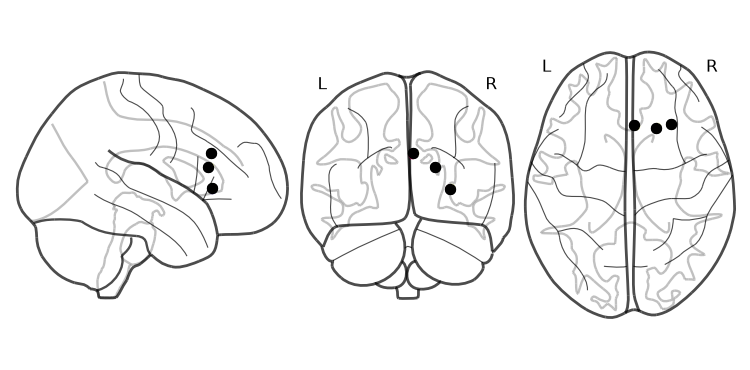

In [9]:
res.plot_nodes()
plt.show()

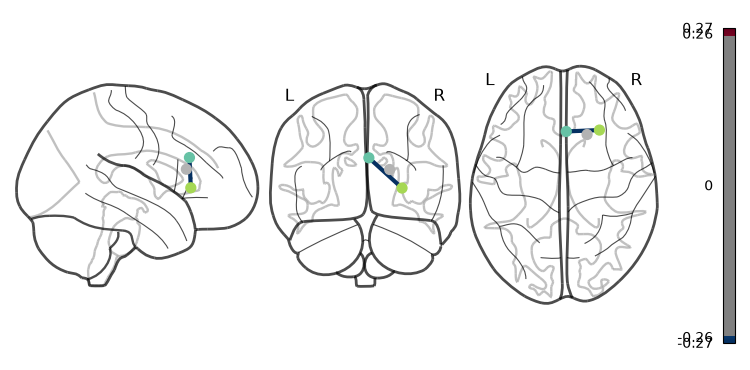

In [10]:
res.plot_connectivity(subject=0)
plt.show()

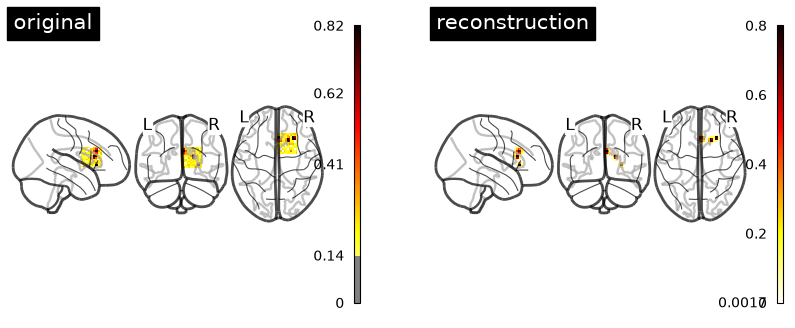

In [11]:
res.plot_reconstruction(subject=0, sample=0)
plt.show()

## Next steps

- `02_tfa_single_subject`: the single-subject estimator and its options.
- `03_htfa_multi_subject`: the hierarchical model, the template and its uncertainty.
- `04_inputs_nifti_folders_nilearn_arrays`: every input type accepted by `htfa.load`.
- The example gallery shows `isfc`, dynamic connectivity and brain-network plots one function at a time.

In [12]:
tmp.cleanup()
print(f"total time of this notebook: {time.perf_counter() - t_notebook:.0f} s")

total time of this notebook: 8 s
